# Single layer — one LDI fit, without energy bias, with it, and with strain

A quick fit for looking at results and tuning, before the ensembles. One LDI
restore event is fitted three times to the sparse observations made by
`03a_single_layer_data`, on **one Fourier band** (the same band, mode count,
directions and seed):

1. **no energy bias, geometry only:** raw cubic modes, every parameter trained
   by Adam from a small random start. Contacts, signed bedding, restored-contact
   flatness and stratigraphic order;
2. **energy bias, geometry only:** the same constraints, trained with the
   energy-biased scheme of `01b`: energy-normalised cubic modes, amplitudes from
   zero by SGD with (Nesterov) momentum, phase and bias by Adam;
3. **energy bias, geometry plus strain:** as 2, with 25 of the 100 marker-cell
   strain ellipses added.

These are member 1 of each of the three ensembles. The band is read off the
data (`curlew.priors.spectral.spectral_band`).

**What this notebook is.** Computation and quick checks only; nothing drawn
here is saved. It writes `results/fit_settings.json`, the basis and training
settings that `03c_single_layer_ensemble` fits its ensembles with, so
what is tuned here is what the ensembles use. The figures are made in
`03d_single_layer_figures.ipynb`.

## Setup

In [1]:
import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import curlew
from curlew.core import CSet, HSet
from curlew.geology import restore
from curlew.geometry import Grid
from curlew.kinematics.euler import euler_velocity
from curlew.kinematics.training import SpectralWarmup
from curlew.priors.spectral import spectral_band, n_features_for_band

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import diagnostics
import figstyle
import single_layer_inputs as sli  # benchmark, observation split and ensemble measures, shared with 03a, 03c and 03d

figstyle.apply()
curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 2

SEED = 404
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT_DIR = Path("results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"device={curlew.device}, dtype={curlew.dtype}")

device=cpu, dtype=torch.float32


## Benchmark and observations

The ground truth and the observation split from 03a, in the frame shifted to
the mean of the digitised contacts; H0 is the uppermost contact.

In [2]:
truth = sli.load_truth()
obs = sli.load_observations(truth)
horizons_full, horizon_names = truth["horizons_full"], truth["horizon_names"]
horizons, gp, gv = obs["horizons"], obs["gp"], obs["gv"]
strain_xy = truth["strain_xy"]
horizon_colors = {n: figstyle.HORIZON_PALETTE[i % len(figstyle.HORIZON_PALETTE)] for i, n in enumerate(horizon_names)}

IQ_SAMPLES = 8
iq_pairs = [(horizons[i], horizons[i + 1], ">") for i in range(len(horizons) - 1)]
C_GEOMETRY = CSet(gp=gp, gv=gv, eq=horizons, iq=(IQ_SAMPLES, iq_pairs))
C_STRAIN = CSet(gp=gp, gv=gv, eq=horizons, iq=(IQ_SAMPLES, iq_pairs), sp=obs["sp"], se=obs["se"], sr=obs["sr"])
anchor = torch.tensor([0.0, 0.0], dtype=curlew.dtype, device=curlew.device)
print(f"contacts {sum(map(len, horizons))} | bedding {len(gp)} | "
      f"strain {len(obs['strain_train_idx'])} in the strain fit, {len(obs['strain_test_idx'])} held out")

contacts 60 | bedding 10 | strain 15 in the strain fit, 85 held out


## Evaluation grid

The ensembles' grid: 4-unit spacing over 1.15 times the extent of the contacts.

In [3]:
pts = np.vstack(horizons_full)
extent = 1.15 * (pts.max(axis=0) - pts.min(axis=0))
G = Grid(tuple(extent), step=(4.0, 4.0), center=(0.0, 0.0), sampleArgs=dict(N=4096))
domaxes = G.tformed_axes
x, z = np.asarray(domaxes[0], dtype=float), np.asarray(domaxes[1], dtype=float)
grid_tensor = torch.as_tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)
print("grid", G.shape)

grid (149, 135)


## The Fourier basis

The band is read off the data's spectral moments: contacts give the variance
of horizon heights (*m*₀), bedding the variance of slopes (*m*₂), neighbouring
bedding the variance of curvatures (*m*₄). *L*min is the shorter of the hinge
spacing 2π√(*m*₂/*m*₄) and the limb spacing 2π√(*m*₀/*m*₂); *L*max the longer,
and at least two octaves above *L*min and the data's diameter.

The strain markers enter too. The moments are measured in the unstrained frame:
the data are pulled back through the bulk strain (the log-Euclidean mean of the
markers' strain), so the wavelengths are those before the homogeneous
shortening (Sherwin & Chapple 1968). And *L*max is at least π*D*/√(2*r*), with
*r* the strain's heterogeneity relative to its mean, so that modes are long
enough to carry the bulk strain. The band is computed from the constraints with
strain and used for **both** fits, so they share one basis. The mode count
follows from the band at a fixed number of modes per octave.

In [4]:
MODES_PER_OCTAVE = 64
N_DIRECTIONS = 32
FOURIER_SEED = 404

LENGTH_SCALE_RANGE, BAND_INFO = spectral_band(C_STRAIN, return_info=True)   # used for both fits
N_FEATURES = n_features_for_band(LENGTH_SCALE_RANGE, MODES_PER_OCTAVE, N_DIRECTIONS)
print(f"band {LENGTH_SCALE_RANGE[0]:.0f}-{LENGTH_SCALE_RANGE[1]:.0f} | M {N_FEATURES} |", BAND_INFO)

/Users/kamath92/anaconda3/envs/curlew_dev/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3701: UserWarning: CSet has crs='global'; spectral_band assumes positions are already in the coordinate system used for fitting. When a GeoModel transform applies, call CSet.to_model(T) or bind through the model first.
  exec(code_obj, self.user_global_ns, self.user_ns)


band 570-2854 | M 160 | {'m0': None, 'm2': 0.04434810133013524, 'm4': 5.397337235728747e-06, 'lambda_x': 569.5444271067206, 'lambda_0': None, 'normal': [0.06954938126468403, 0.9975785099758813], 'normal_from_contacts': False, 'resolved': True, 'lambda_x_error': 0.44174897727033885, 'n_curvature': 9.187988880987781, 'window': 214.7292255965827, 'contact_noise': 0.28927161035701565, 'n_eff': 1.0, 'n_bedding': 10, 'n_contacts': 60, 'n_pairs': 3, 'n_windows': 9, 'n_horizons_spanning': 0, 'profile': False, 'diameter': 988.9816248221628, 'strain': {'X_over_Z': 3.4606097470431183, 'heterogeneity': 0.5926965812359316, 'n_markers': 15, 'L_bulk': 2853.6906106118945, 'F': [[0.538387289117837, -0.03314984239424423], [-0.033149842394244226, 1.859440095049592]]}}


## LDI: no energy bias, energy bias, energy bias and strain

One restore event per case, on the same band and seed, trained as each ensemble
member is. The no-bias case is the plain baseline: its modes are not
energy-normalised and all parameters, amplitudes included, are trained by Adam
from a small random start.

In [5]:
WEIGHTS = dict(grad_loss="1.", eq_loss="0.1")
N_STEPS = 0
INTEGRATOR = "shear"
EPOCHS = 2500
STRAIN_WEIGHT = "0.01"

# Energy-biased training
LR_ADAM = 5e-3          # Adam rate for phase and bias
LR_SGD = 1e-1            # SGD rate for the amplitudes
AMP_MOMENTUM = 0.9
INIT_STD = 0.0

# No energy bias (the plain baseline): raw cubic modes, all parameters by Adam, small random start
LR_PLAIN = 5e-3
INIT_STD_PLAIN = 0.

# Spectral warm-up (curlew.kinematics.training.SpectralWarmup): the octaves of the band are let in from
# the longest to the shortest over the first 1/6 of the epochs, so the long modes get a head start.
SPECTRAL_WARMUP = False


def fit_ldi(include_strain, energy_biased=True):
    velocity = euler_velocity(
        2, n_features=N_FEATURES, n_directions=N_DIRECTIONS, length_scale_range=LENGTH_SCALE_RANGE,
        stream="alpha", activation="cubic", seed=FOURIER_SEED, energy_normalised=energy_biased,
    )
    if energy_biased:
        init_std, lr = INIT_STD, LR_ADAM
        optimizer = {
            "amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM, nesterov=True)),
            "shape": (torch.optim.Adam, dict(lr=LR_ADAM)),
        }
    else:
        init_std, lr, optimizer = INIT_STD_PLAIN, LR_PLAIN, None   # Adam on everything
    kind = "plain" if not energy_biased else "strain" if include_strain else "geometry"
    event = restore(
        f"single_layer_{kind}",
        C=C_STRAIN if include_strain else C_GEOMETRY,
        H=HSet.restore(**WEIGHTS, strain_loss=STRAIN_WEIGHT if include_strain else 0),
        velocity=velocity, n_steps=N_STEPS, depth_axis=1, integrator=INTEGRATOR,
        init_std=init_std, sigma_floor=0.0, signed_normals=True, learning_rate=lr,
        optimizer=optimizer, pin=anchor,
    )
    for hi, trace in enumerate(reversed(horizons)):
        event.addIsosurface(f"horizon_{hi}", seed=trace)
    model = curlew.GeoModel([event])
    with SpectralWarmup(event) as schedule:
        model.prefit(epochs=EPOCHS, vb=True, early_stop=None, best=True,
                     schedule=schedule if SPECTRAL_WARMUP and energy_biased else None)
    return model, event


fits = {"plain": fit_ldi(False, energy_biased=False), "geometry": fit_ldi(False), "strain": fit_ldi(True)}

L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|
L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|
L=0.001 grad_loss=0.000 strain_loss=0.001 eq_loss=0.000: : 2500/2500|


## Check

Scalar field, lithology and interior extrema of the three fits, against the true
contacts (dashed). Also the restored-horizon flatness, the bulk shortening
against Hudleston's *S* = 6, and the held-out strain errors, as the ensembles
report them.

plain: maxima=0, minima=0, saddles=0 | restored flatness 2.19 | S per horizon [3.2, 7.8, 11.3, 10.9, 8.8, 3.0] (Hudleston 6)
   held-out log stretch RMSE 1.615, axis error (degrees) 32.969, shape-tensor RMSE 8.690
geometry: maxima=0, minima=0, saddles=0 | restored flatness 4.12 | S per horizon [1.1, 2.3, 3.0, 2.8, 2.4, 1.5] (Hudleston 6)
   held-out log stretch RMSE 0.777, axis error (degrees) 15.870, shape-tensor RMSE 1.539
strain: maxima=0, minima=0, saddles=0 | restored flatness 3.45 | S per horizon [3.5, 3.8, 4.0, 4.0, 4.0, 4.1] (Hudleston 6)
   held-out log stretch RMSE 0.535, axis error (degrees) 7.459, shape-tensor RMSE 0.960


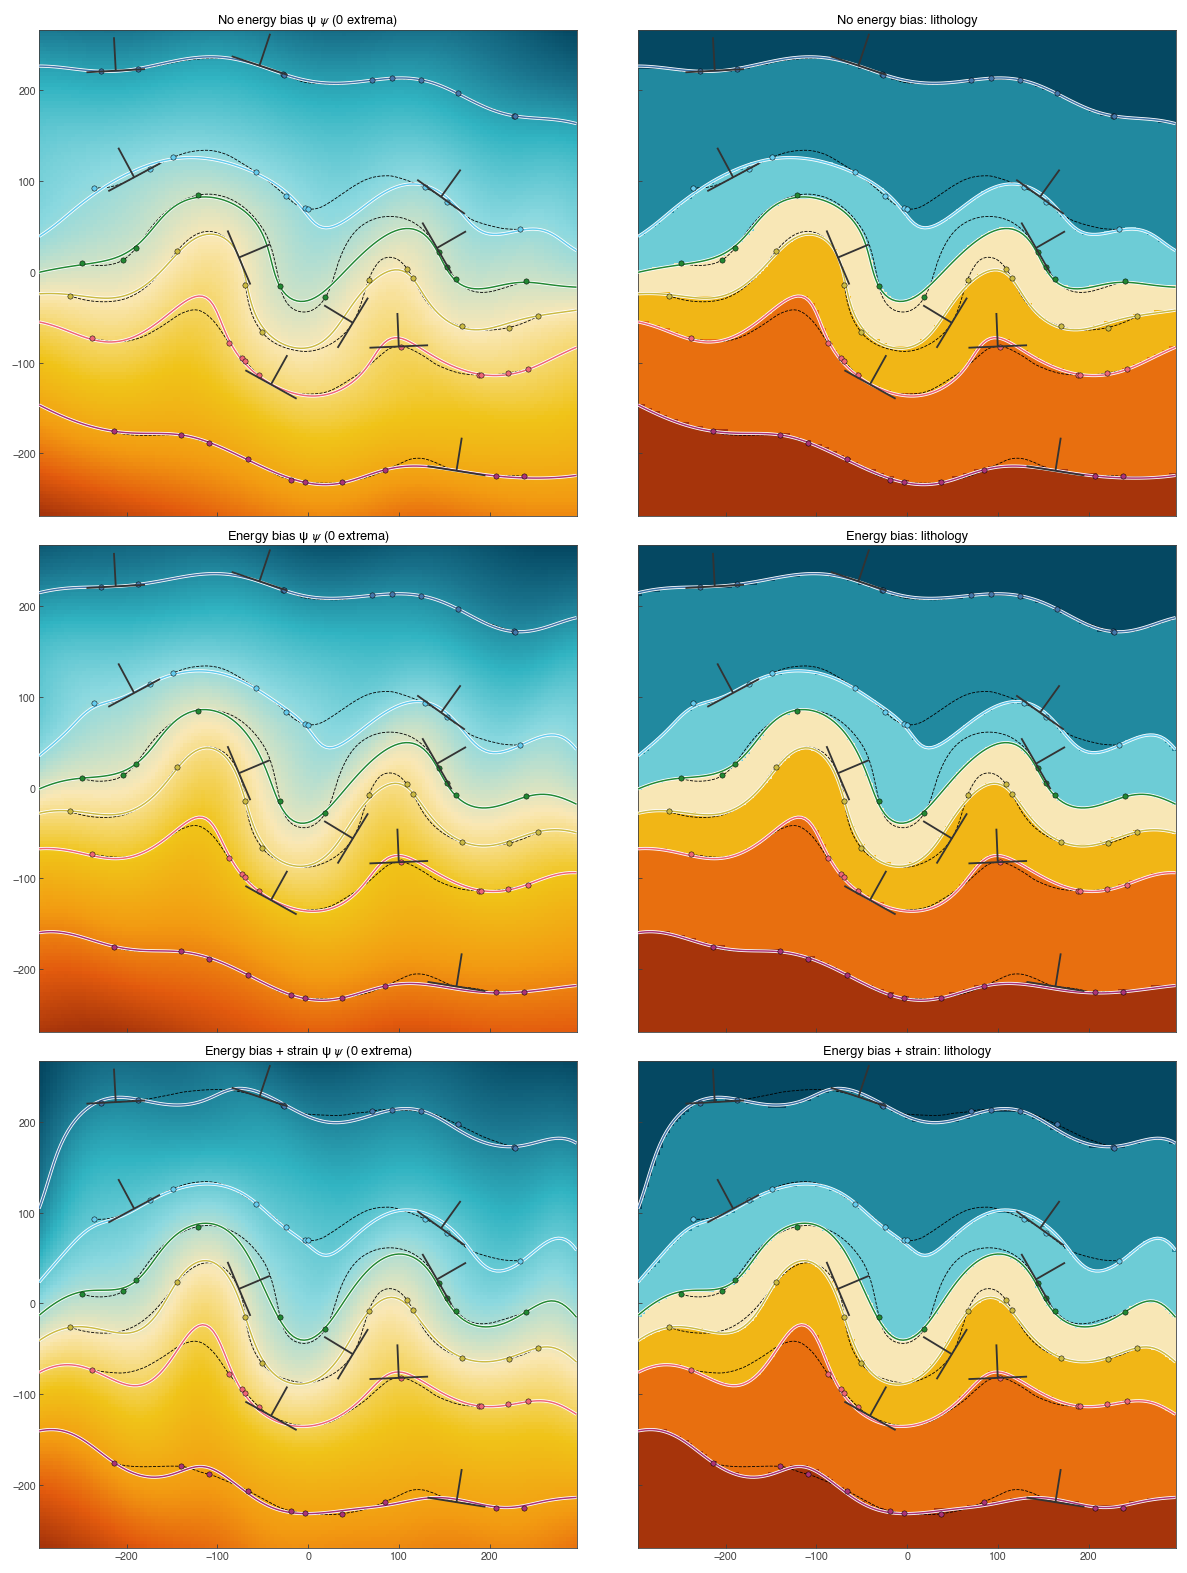

In [6]:
def evaluate(model, event):
    with torch.no_grad():
        geode = model.predict(grid_tensor, litho=True)
    scalar = np.asarray(G.reshape(geode.scalar), dtype=float)
    litho = np.asarray(G.reshape(geode.lithoID))
    n = len(horizons)
    iso = [event.getIsovalue(f"horizon_{n - 1 - i}") for i in range(n)]   # in horizon order
    crit = diagnostics.find_critical_points(event, x, z)
    field = event.field
    with torch.no_grad():
        restored = np.stack([field.total_inverse_map(torch.as_tensor(t, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
                             for t in horizons_full])
        _x0, J = field.total_inverse_map_with_jacobian(torch.as_tensor(strain_xy, dtype=curlew.dtype, device=curlew.device))
        F_map = torch.linalg.inv(J)
        B = F_map @ F_map.transpose(-1, -2)
        B = (B / torch.linalg.det(B).clamp_min(1e-12).sqrt()[:, None, None]).cpu().numpy()
    return dict(scalar=scalar, litho=litho, iso=iso, crit=crit, restored=restored, B=B)


results = {key: evaluate(*fit) for key, fit in fits.items()}
for key, r in results.items():
    crit = r["crit"]
    spread = sli.restored_horizon_spread(r["restored"][None])
    bulk = sli.bulk_shortening(horizons_full, r["restored"][None])
    held = sli.heldout_metrics(r["B"][None], truth, obs["strain_test_idx"])
    print(f"{key}: maxima={crit.counts['maximum']}, minima={crit.counts['minimum']}, saddles={crit.counts['saddle']} | "
          f"restored flatness {float(np.mean(spread['flatness'])):.2f} | S per horizon "
          f"{np.round(bulk['S'][0], 1).tolist()} (Hudleston {sli.HUDLESTON_S:g})")
    print("   held-out " + ", ".join(f"{name} {float(np.mean(v)):.3f}" for name, v in held.items()))

cmap_litho, norm_litho = figstyle.litho_cmap(np.unique(np.concatenate([r["litho"].ravel() for r in results.values()])))
extent = (x[0], x[-1], z[0], z[-1])
fig, axs = plt.subplots(3, 2, figsize=(10, 13), sharex=True, sharey=True, constrained_layout=True)
for row, (key, label) in enumerate((("plain", "No energy bias"), ("geometry", "Energy bias"), ("strain", "Energy bias + strain"))):
    r = results[key]
    ax = axs[row, 0]
    ax.imshow(r["scalar"].T, origin="lower", extent=extent, cmap=figstyle.ramp(), interpolation="nearest")
    figstyle.draw_contact_contours(ax, x, z, r["scalar"], horizons, horizon_names, colors=horizon_colors, levels=r["iso"])
    diagnostics.overlay_critical_points(ax, r["crit"], size=24)
    ax.set_title(diagnostics.extrema_title(f"{label} ψ", r["crit"]))
    ax = axs[row, 1]
    ax.imshow(r["litho"].T, origin="lower", extent=extent, cmap=cmap_litho, norm=norm_litho, interpolation="nearest")
    figstyle.draw_contact_contours(ax, x, z, r["scalar"], horizons, horizon_names, colors=horizon_colors, levels=r["iso"])
    ax.set_title(f"{label}: lithology")
for ax in axs.ravel():
    for trace in horizons_full:
        ax.plot(trace[:, 0], trace[:, 1], color="k", lw=0.5, ls="--")
    figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv, colors=horizon_colors,
                                 scatter_s=10, quiver_scale=0.013)
    ax.set_aspect("equal")
plt.show()

## Save

The basis and training settings, which `03c_single_layer_ensemble` reads.

In [7]:
(OUT_DIR / "fit_settings.json").write_text(json.dumps(dict(
    fourier_seed=FOURIER_SEED, n_features=N_FEATURES, n_directions=N_DIRECTIONS,
    length_scale_range=list(LENGTH_SCALE_RANGE), modes_per_octave=MODES_PER_OCTAVE, band_info=BAND_INFO,
    n_steps=N_STEPS, integrator=INTEGRATOR, epochs=EPOCHS, weights=WEIGHTS, strain_weight=STRAIN_WEIGHT,
    iq_samples=IQ_SAMPLES, energy_normalised=True, init_std=INIT_STD,
    lr_adam=LR_ADAM, lr_sgd=LR_SGD, amp_momentum=AMP_MOMENTUM, spectral_warmup=SPECTRAL_WARMUP,
    lr_plain=LR_PLAIN, init_std_plain=INIT_STD_PLAIN,
), indent=2))
print("wrote", OUT_DIR / "fit_settings.json")

wrote results/fit_settings.json
